# Preprocessing, physics-guided features, and immutable specimen-group folds

**Scientific goal.** Convert the audited DaKS table into one reproducible modeling contract without leakage. **Input from Notebook 01.** The clean primary dataset, permitted predictors, specimen grouping, and research design. **Allowed data.** All 81 primary 51CrV4 observations only. **Methods.** Physically justified deterministic features, dependency analysis, and balanced nested specimen-group CV assignment. **Output to Notebook 03.** The immutable primary modeling contract used by every model family.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain.


## Stage decision

The small dataset cannot support a scientifically honest train/validation/locked-test fragmentation after all rows have already informed the exploratory redesign. Nine specimen-group outer folds provide the generalization estimate; four group-aware inner folds perform tuning. The outer held-out rows are never used for preprocessing or model selection within their fold.


## 1. Load the audited dataset and define the modeling scope


In [1]:
from pathlib import Path
import warnings

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
SEED = 20260820
RUN_ID = "FA_ATF_DaKS69_Exploratory_20260820"

ROOT = Path.cwd().resolve()
if not (ROOT / "dataset").exists() and (ROOT.parent / "dataset").exists():
    ROOT = ROOT.parent

RAW_PATH = ROOT / "dataset" / "raw" / "hardness_roughness_hard_turning.csv"
UNIFIED_DIR = ROOT / "dataset" / "unified"
RUN_ROOT = ROOT / "artifacts" / RUN_ID
FIGURE_PNG_DIR = RUN_ROOT / "Figures" / "PNG"
FIGURE_PDF_DIR = RUN_ROOT / "Figures" / "PDF"
FIGURE_SOURCE_DIR = RUN_ROOT / "Tables" / "Figure_Source_Data"
AUDIT_DIR = RUN_ROOT / "Tables" / "Audit"

for directory in (UNIFIED_DIR, FIGURE_PNG_DIR, FIGURE_PDF_DIR, FIGURE_SOURCE_DIR, AUDIT_DIR):
    directory.mkdir(parents=True, exist_ok=True)



# Publication-table presentation helper. It changes display only; values are untouched.
def display_grouped_table(
    frame,
    title=None,
    identifier_columns=None,
    column_groups=None,
    row_group_columns=None,
    max_rows_per_block=12,
):
    table = frame.copy()

    def _identifier_columns(columns):
        priorities = [
            "model", "model_family", "rank", "target", "Target", "variant", "Variant",
            "ablation", "comparison", "Comparison", "comparator", "Comparator",
            "class", "Class", "factor", "factor_label", "level", "condition",
            "distance_band", "metric", "Metric", "component",
            "candidate", "expert", "outer_fold", "inner_fold", "fold",
            "Feature", "feature", "Predictor", "predictor", "Variable",
            "variable", "Field", "Decision", "Analysis item", "Scientific conclusion",
            "Scientific property", "Quantity", "Scaler", "Contract item", "criterion",
            "Column", "item", "sample_id", "specimen_id", "section_id",
        ]
        selected = [column for column in priorities if column in columns]
        return selected[:4]

    def _column_groups(columns, identifiers):
        remaining = [column for column in columns if column not in identifiers]
        if len(columns) <= 7:
            return [("Complete table", remaining)]
        rules = [
            ("Predictors and design variables", (
                "hv_init", "feed", "cutting_speed", "depth_of_cut", "uncut_chip",
                "material_removal", "theoretical_roughness", "predictor", "factor",
                "formula", "unit", "level", "role", "definition", "available",
            )),
            ("Measured responses", (
                "surface_roughness", "post_process_hardness", "y_true", "y_pred",
                "lower_90", "upper_90",
            )),
            ("Predictive performance", (
                "mae", "rmse", "nrmse", "r2", "macro", "bias", "error",
                "rank", "score",
            )),
            ("Uncertainty and statistical evidence", (
                "ci_", "_ci", "confidence", "bootstrap", "coverage", "interval",
                "wilcoxon", "holm", "p_value", "_p", "probability", "effect",
                "delta", "median_fold", "sign_flip", "quantile",
            )),
            ("Computational efficiency", (
                "time", "latency", "parameter", "memory", "byte", "epoch",
                "inference", "fit_seconds", "complexity",
            )),
            ("Sample, fold, and provenance", (
                "observation", "specimen", "sample", "section", "fold", "seed",
                "rows", "columns", "matrix_rank", "condition_number", "replicate",
                "minimum", "maximum", "median", "mean", "std", "sd", "skew",
                "count", "n_", "status", "retained", "selected", "interpretation",
                "requirement", "evidence", "value",
            )),
        ]
        assigned = set()
        grouped = []
        for label, tokens in rules:
            members = [
                column for column in remaining
                if column not in assigned
                and any(token in str(column).lower() for token in tokens)
            ]
            if members:
                grouped.append((label, members))
                assigned.update(members)
        leftovers = [column for column in remaining if column not in assigned]
        if leftovers:
            grouped.append(("Additional reported attributes", leftovers))
        return grouped or [("Complete table", remaining)]

    def _split_wide_groups(groups):
        split_groups = []
        for label, columns in groups:
            if len(columns) <= 5:
                split_groups.append((label, columns))
                continue
            part_count = (len(columns) + 4) // 5
            for part_index in range(part_count):
                start = part_index * 5
                split_groups.append((
                    f"{label} (part {part_index + 1}/{part_count})",
                    columns[start:start + 5],
                ))
        return split_groups

    identifiers = (
        [column for column in identifier_columns if column in table.columns]
        if identifier_columns is not None
        else _identifier_columns(list(table.columns))
    )
    groups = (
        [(label, [column for column in columns if column in table.columns])
         for label, columns in column_groups]
        if column_groups is not None
        else _column_groups(list(table.columns), identifiers)
    )
    groups = _split_wide_groups([(label, columns) for label, columns in groups if columns])

    represented = set(identifiers)
    for _, columns in groups:
        represented.update(columns)
    missing = [column for column in table.columns if column not in represented]
    if missing:
        groups.extend(_split_wide_groups([("Additional reported attributes", missing)]))
    assert represented.union(missing) == set(table.columns)

    if row_group_columns is None and len(table) > max_rows_per_block:
        candidates = [
            "model_family", "target", "factor", "condition", "distance_band",
            "Role", "role", "component", "outer_fold", "variant", "comparator",
        ]
        row_group_columns = []
        for column in candidates:
            if column not in table.columns or column in row_group_columns:
                continue
            unique_count = table[column].nunique(dropna=False)
            if 1 < unique_count <= 10:
                row_group_columns.append(column)
                largest = table.groupby(row_group_columns, dropna=False, sort=False).size().max()
                if largest <= max_rows_per_block:
                    break
    row_group_columns = [
        column for column in (row_group_columns or []) if column in table.columns
    ]
    if row_group_columns:
        row_groups = list(table.groupby(row_group_columns, dropna=False, sort=False))
    elif len(table) > max_rows_per_block:
        row_groups = []
        for start in range(0, len(table), max_rows_per_block):
            stop = min(start + max_rows_per_block, len(table))
            noun = "models" if "model" in table.columns else "records"
            row_groups.append((
                f"{noun} {start + 1}-{stop} in displayed order",
                table.iloc[start:stop],
            ))
    else:
        row_groups = [(None, table)]

    for row_key, row_part in row_groups:
        if row_group_columns:
            values = row_key if isinstance(row_key, tuple) else (row_key,)
            row_label = "; ".join(
                f"{column}={value}" for column, value in zip(row_group_columns, values)
            )
        else:
            row_label = row_key
        for group_label, columns in groups:
            selected_columns = list(dict.fromkeys(identifiers + columns))
            heading = " — ".join(
                item for item in (title, row_label, group_label) if item
            )
            display(Markdown(f"**{heading or 'Complete table'}**"))
            with pd.option_context(
                "display.max_rows", len(row_part),
                "display.max_columns", len(selected_columns),
                "display.max_colwidth", None,
                "display.width", None,
            ):
                display(row_part[selected_columns].style.hide(axis="index"))


def display_complete_table(frame, title=None):
    """Backward-compatible alias for table cells colocated with unchanged figures."""
    return display_grouped_table(frame, title=title)


In [2]:
REQUIRED_FONT = "Times New Roman"
if REQUIRED_FONT not in {font.name for font in font_manager.fontManager.ttflist}:
    raise RuntimeError("Times New Roman is required for publication figures.")

mpl.rcParams.update({
    "font.family": REQUIRED_FONT,
    "font.serif": [REQUIRED_FONT],
    "mathtext.fontset": "custom",
    "mathtext.rm": REQUIRED_FONT,
    "mathtext.it": REQUIRED_FONT + ":italic",
    "mathtext.bf": REQUIRED_FONT + ":bold",
    "font.size": 16,
    "axes.titlesize": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 18,
    "figure.dpi": 350,
    "savefig.dpi": 350,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "text.color": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "axes.grid": True,
    "axes.unicode_minus": True,
    "grid.color": "#D9DDE1",
    "grid.alpha": 0.65,
    "lines.linewidth": 2.0,
    "lines.markersize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

PALETTE = {
    "blue": "#2F6B8F", "orange": "#C77C2B", "green": "#4F7F3A",
    "purple": "#6D5A8D", "red": "#B45A55", "gray": "#6E7378",
    "teal": "#4A8C8A", "gold": "#C9A227", "black": "#222222",
}


def format_scientific_number(value, decimals=2, show_plus=False):
    """Format signed values with U+2212 and suppress rounded negative zero."""
    rounded_value = round(float(value), decimals)
    if rounded_value == 0.0:
        return f"{0.0:.{decimals}f}"
    format_specifier = f"+.{decimals}f" if show_plus else f".{decimals}f"
    return format(rounded_value, format_specifier).replace("-", "−")


def save_scientific_figure(fig, stem, source_frame):
    source_frame.to_csv(FIGURE_SOURCE_DIR / f"{stem}.csv", index=False)
    fig.savefig(
        FIGURE_PNG_DIR / f"{stem}.png", dpi=350, bbox_inches="tight",
        pad_inches=0.08, facecolor="white",
    )
    return FIGURE_PNG_DIR / f"{stem}.png"


In [3]:
from sklearn.preprocessing import RobustScaler, StandardScaler

input_path = UNIFIED_DIR / "unified_dataset.csv"
if not input_path.exists():
    raise FileNotFoundError("Run Notebook 01 before Notebook 02.")
audited = pd.read_csv(input_path)

PREDICTORS = ["HV_init_HV30", "feed_mm_rev", "cutting_speed_m_min", "depth_of_cut_mm"]
TARGETS = ["surface_roughness_Ra_um", "post_process_hardness_HV30"]
modeling = audited[["specimen_id", "section_id"] + PREDICTORS + TARGETS].copy()
modeling.insert(0, "sample_id", np.arange(1, len(modeling) + 1, dtype=int))
assert modeling.shape == (81, 9)
assert modeling[PREDICTORS].drop_duplicates().shape[0] == 81
display_grouped_table(modeling.head(8), "Audited modeling input")


**Audited modeling input — Predictors and design variables**

sample_id,specimen_id,section_id,HV_init_HV30,feed_mm_rev,cutting_speed_m_min,depth_of_cut_mm
1,03-008,3,400,0.050000,100,0.050000
2,03-008,2,400,0.050000,100,0.250000
3,03-008,1,400,0.050000,100,0.500000
4,03-007,3,400,0.250000,100,0.050000
5,03-007,2,400,0.250000,100,0.250000
6,03-007,1,400,0.250000,100,0.500000
7,03-022,3,400,0.500000,100,0.050000
8,03-022,2,400,0.500000,100,0.250000


**Audited modeling input — Measured responses**

sample_id,specimen_id,section_id,surface_roughness_Ra_um,post_process_hardness_HV30
1,03-008,3,0.147000,490
2,03-008,2,0.144000,498
3,03-008,1,0.226000,482
4,03-007,3,0.654000,487
5,03-007,2,0.746000,505
6,03-007,1,0.796000,496
7,03-022,3,2.119000,511
8,03-022,2,2.315000,491


All 81 audited observations enter preprocessing, with stable row identifiers used only to reconcile OOF predictions. `specimen_id` is retained solely as the split group, and `section_id` is excluded from predictors because depth of cut already defines the section condition. No missing-value method or outcome-derived feature is required.


## 2. Confirm factorial coverage and the specimen hierarchy

The experiment is treated as a balanced hierarchical split-plot factorial study rather than 81 exchangeable
rows. Coverage, balance, orthogonal contrast rank, and within-specimen variation are quantified
before any preprocessing choice. These checks determine the correct independent unit and the
amount of information available for model assessment.


In [4]:
from itertools import combinations

FACTOR_LABELS = {
    "HV_init_HV30": "Initial hardness (HV30)",
    "feed_mm_rev": "Feed rate (mm/rev)",
    "cutting_speed_m_min": "Cutting speed (m/min)",
    "depth_of_cut_mm": "Depth of cut (mm)",
}

factor_levels = {factor: np.sort(modeling[factor].unique()) for factor in PREDICTORS}
expected_runs = int(np.prod([len(levels) for levels in factor_levels.values()]))
pair_rows = []
for first, second in combinations(PREDICTORS, 2):
    counts = modeling.groupby([first, second]).size()
    pair_rows.append({
        "factor_pair": f"{FACTOR_LABELS[first]} × {FACTOR_LABELS[second]}",
        "observed_cells": int(len(counts)),
        "expected_cells": int(len(factor_levels[first]) * len(factor_levels[second])),
        "minimum_rows_per_cell": int(counts.min()),
        "maximum_rows_per_cell": int(counts.max()),
    })

factorial_coverage = pd.DataFrame([{
    "observations": len(modeling),
    "independent_specimens": modeling.specimen_id.nunique(),
    "levels_per_factor": " × ".join(str(len(factor_levels[f])) for f in PREDICTORS),
    "expected_full_factorial_runs": expected_runs,
    "unique_four_factor_combinations": modeling[PREDICTORS].drop_duplicates().shape[0],
    "replicates_per_four_factor_combination": 1,
    "complete_factorial_coverage": modeling[PREDICTORS].drop_duplicates().shape[0] == expected_runs,
}])
pairwise_coverage = pd.DataFrame(pair_rows)
factorial_coverage.to_csv(AUDIT_DIR / "factorial_design_coverage.csv", index=False)
pairwise_coverage.to_csv(AUDIT_DIR / "factorial_pairwise_balance.csv", index=False)
display_grouped_table(factorial_coverage, "Full-factorial coverage")
display_grouped_table(pairwise_coverage, "Two-factor balance")


**Full-factorial coverage — Complete table (part 1/2)**

observations,independent_specimens,levels_per_factor,expected_full_factorial_runs,unique_four_factor_combinations
81,27,3 × 3 × 3 × 3,81,81


**Full-factorial coverage — Complete table (part 2/2)**

replicates_per_four_factor_combination,complete_factorial_coverage
1,True


**Two-factor balance — Complete table**

factor_pair,observed_cells,expected_cells,minimum_rows_per_cell,maximum_rows_per_cell
Initial hardness (HV30) × Feed rate (mm/rev),9,9,9,9
Initial hardness (HV30) × Cutting speed (m/min),9,9,9,9
Initial hardness (HV30) × Depth of cut (mm),9,9,9,9
Feed rate (mm/rev) × Cutting speed (m/min),9,9,9,9
Feed rate (mm/rev) × Depth of cut (mm),9,9,9,9
Cutting speed (m/min) × Depth of cut (mm),9,9,9,9


In [5]:
nesting_rows = []
for factor in PREDICTORS:
    within_counts = modeling.groupby("specimen_id")[factor].nunique()
    nesting_rows.append({
        "variable": FACTOR_LABELS[factor],
        "minimum_levels_within_specimen": int(within_counts.min()),
        "maximum_levels_within_specimen": int(within_counts.max()),
        "specimens_with_one_level": int((within_counts == 1).sum()),
        "specimens_with_three_levels": int((within_counts == 3).sum()),
        "hierarchical_role": "within-specimen section factor" if factor == "depth_of_cut_mm" else "between-specimen profile factor",
    })

specimen_rows = modeling.groupby("specimen_id").size()
specimen_structure = pd.DataFrame(nesting_rows)
specimen_structure["rows_per_specimen_min"] = int(specimen_rows.min())
specimen_structure["rows_per_specimen_max"] = int(specimen_rows.max())
specimen_structure.to_csv(AUDIT_DIR / "specimen_nesting_structure.csv", index=False)
display_grouped_table(specimen_structure, "Measured-factor hierarchy")


**Measured-factor hierarchy — Predictors and design variables**

variable,minimum_levels_within_specimen,maximum_levels_within_specimen,specimens_with_one_level,specimens_with_three_levels,hierarchical_role
Initial hardness (HV30),1,1,27,0,between-specimen profile factor
Feed rate (mm/rev),1,1,27,0,between-specimen profile factor
Cutting speed (m/min),1,1,27,0,between-specimen profile factor
Depth of cut (mm),3,3,0,27,within-specimen section factor


**Measured-factor hierarchy — Uncertainty and statistical evidence**

variable,rows_per_specimen_min,rows_per_specimen_max
Initial hardness (HV30),3,3
Feed rate (mm/rev),3,3
Cutting speed (m/min),3,3
Depth of cut (mm),3,3


In [6]:
contrast_columns = [np.ones(len(modeling))]
factor_contrasts = {}
linear = np.array([-1.0, 0.0, 1.0]) / np.sqrt(2.0)
quadratic = np.array([1.0, -2.0, 1.0]) / np.sqrt(6.0)

for factor in PREDICTORS:
    mapping = {
        level: (linear[level_index], quadratic[level_index])
        for level_index, level in enumerate(factor_levels[factor])
    }
    values = np.array([mapping[value] for value in modeling[factor]])
    factor_contrasts[factor] = values
    contrast_columns.extend([values[:, 0], values[:, 1]])

for first, second in combinations(PREDICTORS, 2):
    for first_order in range(2):
        for second_order in range(2):
            contrast_columns.append(
                factor_contrasts[first][:, first_order]
                * factor_contrasts[second][:, second_order]
            )


In [7]:
factorial_matrix = np.column_stack(contrast_columns)
conditioning = pd.DataFrame([{
    "design_representation": "Orthogonal main and two-factor polynomial contrasts",
    "columns": factorial_matrix.shape[1],
    "matrix_rank": int(np.linalg.matrix_rank(factorial_matrix)),
    "condition_number": float(np.linalg.cond(factorial_matrix)),
    "interpretation": "Full rank for all main and two-factor effects",
}])
conditioning.to_csv(AUDIT_DIR / "factorial_design_conditioning.csv", index=False)
display_grouped_table(conditioning.round(4), "Factorial design-matrix identifiability")


**Factorial design-matrix identifiability — Complete table**

design_representation,columns,matrix_rank,condition_number,interpretation
Orthogonal main and two-factor polynomial contrasts,33,33,3.000000,Full rank for all main and two-factor effects


The 81 rows form the complete (3^4) factorial grid, and every two-factor cell is equally
represented. However, this does not imply 81 independent experimental units: initial hardness,
feed, and cutting speed are fixed within each physical specimen, while depth of cut indexes the
three section conditions. Consequently, specimen-group resampling is required throughout.


## 3. Quantify within-specimen dependence

A descriptive one-way intraclass correlation coefficient (ICC) is estimated for each target,
with a whole-specimen bootstrap. The ICC is used only to quantify within-specimen dependence;
it is not a causal variance decomposition and is not converted into an approximate effective sample size.


In [8]:
def one_way_icc(profile_matrix):
    group_count, sections = profile_matrix.shape
    grand_mean = profile_matrix.mean()
    group_means = profile_matrix.mean(axis=1)
    between_ms = sections * np.sum((group_means - grand_mean) ** 2) / (group_count - 1)
    within_ms = np.sum((profile_matrix - group_means[:, None]) ** 2) / (group_count * (sections - 1))
    denominator = between_ms + (sections - 1) * within_ms
    return float((between_ms - within_ms) / denominator)


ICC_BOOTSTRAPS = 5000
icc_rng = np.random.default_rng(SEED + 202)
icc_rows = []
for target in TARGETS:
    profiles = (
        modeling.pivot(index="specimen_id", columns="section_id", values=target)
        .sort_index().to_numpy()
    )
    assert profiles.shape == (27, 3) and not np.isnan(profiles).any()
    observed_icc = one_way_icc(profiles)
    bootstrap_values = np.empty(ICC_BOOTSTRAPS)
    for bootstrap_index in range(ICC_BOOTSTRAPS):
        sampled_groups = icc_rng.integers(0, len(profiles), size=len(profiles))
        bootstrap_values[bootstrap_index] = one_way_icc(profiles[sampled_groups])
    icc_rows.append({
        "target": target,
        "observations": profiles.size,
        "specimens": profiles.shape[0],
        "sections_per_specimen": profiles.shape[1],
        "ICC": observed_icc,
        "ICC_CI_low": np.quantile(bootstrap_values, 0.025),
        "ICC_CI_high": np.quantile(bootstrap_values, 0.975),
        "bootstrap_resamples": ICC_BOOTSTRAPS,
    })

icc_summary = pd.DataFrame(icc_rows)
icc_summary.to_csv(AUDIT_DIR / "specimen_icc_with_bootstrap.csv", index=False)
display_grouped_table(icc_summary.round(4), "Specimen-level dependence")


**Specimen-level dependence — Uncertainty and statistical evidence**

target,sections_per_specimen,ICC_CI_low,ICC_CI_high,bootstrap_resamples
surface_roughness_Ra_um,3,0.979900,0.994900,5000
post_process_hardness_HV30,3,0.843900,0.952200,5000


**Specimen-level dependence — Sample, fold, and provenance**

target,observations,specimens
surface_roughness_Ra_um,81,27
post_process_hardness_HV30,81,27


**Specimen-level dependence — Additional reported attributes**

target,ICC
surface_roughness_Ra_um,0.991000
post_process_hardness_HV30,0.910800


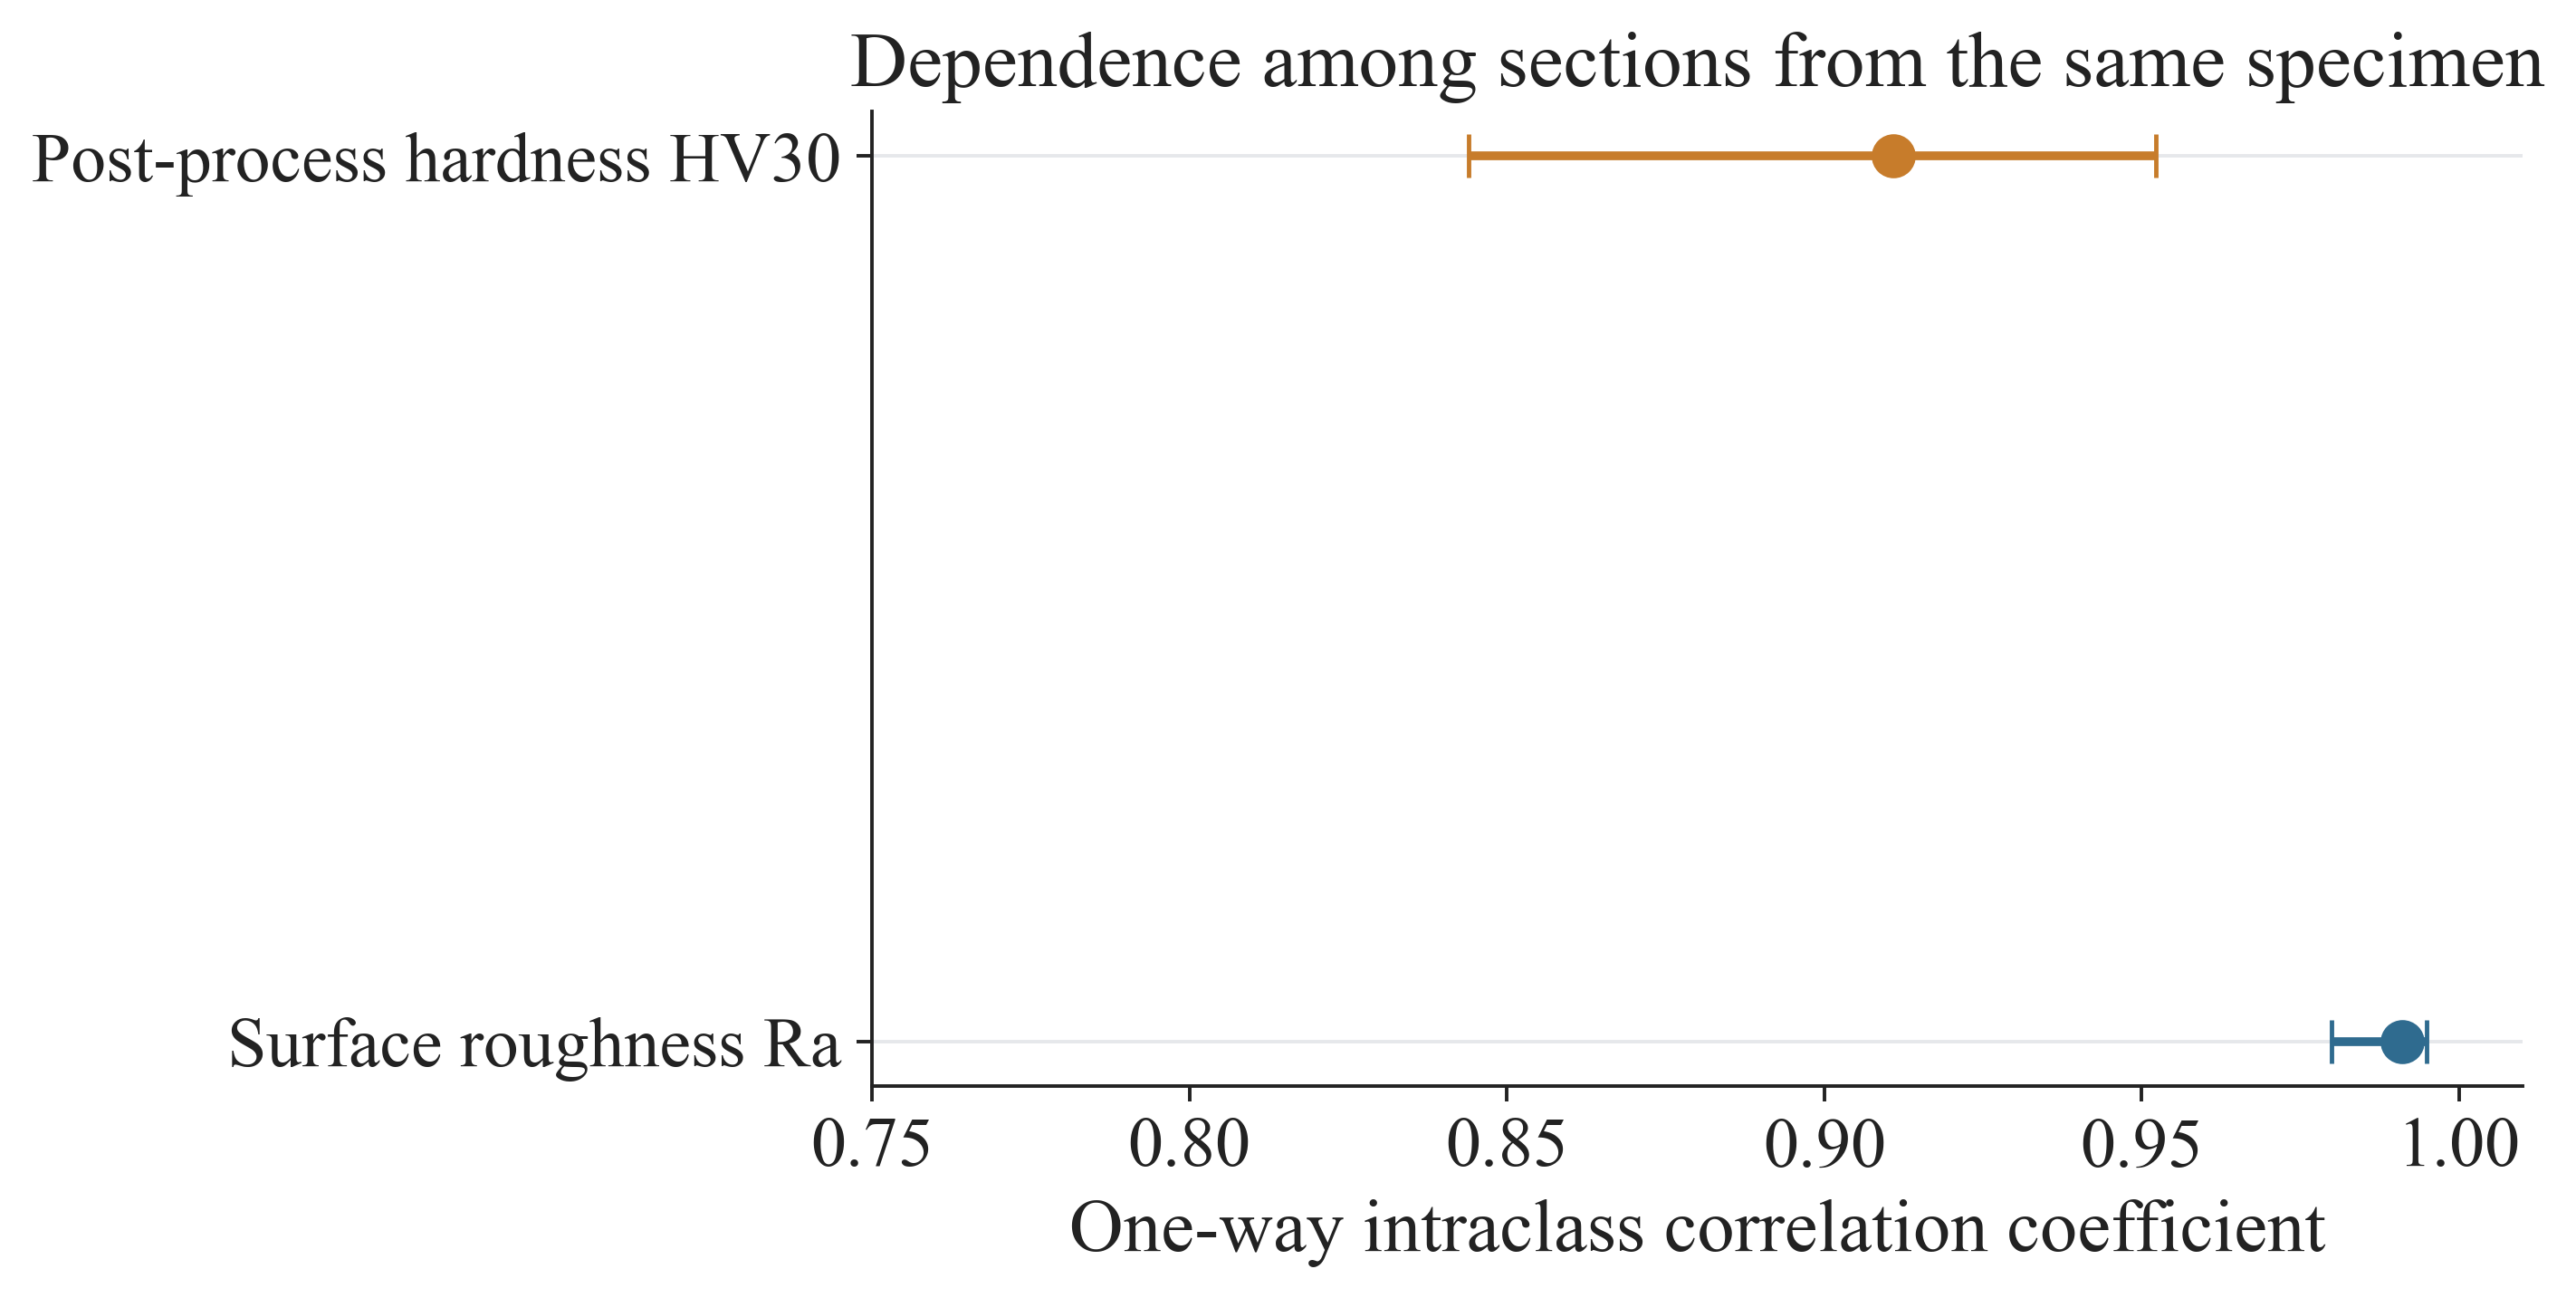

In [9]:
icc_plot = icc_summary.copy()
icc_plot["target_label"] = icc_plot.target.map({
    TARGETS[0]: "Surface roughness Ra",
    TARGETS[1]: "Post-process hardness HV30",
})
fig, axis = plt.subplots(figsize=(8.4, 4.8))
for row_index, row in icc_plot.iterrows():
    axis.errorbar(
        row.ICC, row_index,
        xerr=[[row.ICC - row.ICC_CI_low], [row.ICC_CI_high - row.ICC]],
        fmt="o", color=[PALETTE["blue"], PALETTE["orange"]][row_index],
        capsize=5, markersize=9,
    )
axis.set_yticks(range(len(icc_plot)), labels=icc_plot.target_label)
axis.set_xlim(0.75, 1.01)
axis.set_xlabel("One-way intraclass correlation coefficient")
axis.set_ylabel("")
axis.set_title("Dependence among sections from the same specimen")
axis.grid(axis="x")
fig.subplots_adjust(left=0.36, right=0.98, bottom=0.20, top=0.84)
save_scientific_figure(fig, "preprocessing_specimen_icc", icc_plot)
display(fig)
plt.close(fig)


In [10]:
strongest = icc_summary.sort_values("ICC", ascending=False).iloc[0]
display(Markdown(
    f"**Interpretation.** Within-specimen dependence is strong for both targets; the largest "
    f"descriptive ICC is {strongest.ICC:.3f} for `{strongest.target}`. This dependence supports "
    "the pre-specified specimen grouping but does not supply a formal effective sample size. "
    "All subsequent splitting, bootstrap inference, and paired tests must "
    "therefore operate on whole specimens."
))


**Interpretation.** Within-specimen dependence is strong for both targets; the largest descriptive ICC is 0.991 for `surface_roughness_Ra_um`. This dependence supports the pre-specified specimen grouping but does not supply a formal effective sample size. All subsequent splitting, bootstrap inference, and paired tests must therefore operate on whole specimens.

## 4. Add only justified deterministic process features


In [11]:
TOOL_CORNER_RADIUS_MM = 0.8
modeling["uncut_chip_section_mm2"] = modeling.feed_mm_rev * modeling.depth_of_cut_mm
modeling["material_removal_proxy_mm3_min"] = (
    1000.0 * modeling.cutting_speed_m_min * modeling.feed_mm_rev * modeling.depth_of_cut_mm
)
modeling["theoretical_roughness_Ra_um"] = (
    modeling.feed_mm_rev.pow(2) / (32.0 * TOOL_CORNER_RADIUS_MM) * 1000.0
)

DERIVED_FEATURES = [
    "uncut_chip_section_mm2", "material_removal_proxy_mm3_min",
    "theoretical_roughness_Ra_um",
]
FEATURES = PREDICTORS + DERIVED_FEATURES
derived_summary = pd.DataFrame([
    {"Feature": "uncut_chip_section_mm2", "Formula": "f × a_p", "Unit": "mm²", "Role": "Uncut-chip-section proxy"},
    {"Feature": "material_removal_proxy_mm3_min", "Formula": "1000 × v_c × f × a_p", "Unit": "mm³/min", "Role": "Material-removal proxy"},
    {"Feature": "theoretical_roughness_Ra_um", "Formula": "f² / (32 × 0.8 mm) × 1000", "Unit": "µm", "Role": "Kinematic roughness proxy"},
])
display_grouped_table(derived_summary, "Physics-guided feature definitions")
display_grouped_table(modeling[["sample_id"] + DERIVED_FEATURES].head(8), "Derived feature values")


**Physics-guided feature definitions — Complete table**

Feature,Formula,Unit,Role
uncut_chip_section_mm2,f × a_p,mm²,Uncut-chip-section proxy
material_removal_proxy_mm3_min,1000 × v_c × f × a_p,mm³/min,Material-removal proxy
theoretical_roughness_Ra_um,f² / (32 × 0.8 mm) × 1000,µm,Kinematic roughness proxy


**Derived feature values — Complete table**

sample_id,uncut_chip_section_mm2,material_removal_proxy_mm3_min,theoretical_roughness_Ra_um
1,0.002500,250.000000,0.097656
2,0.012500,1250.000000,0.097656
3,0.025000,2500.000000,0.097656
4,0.012500,1250.000000,2.441406
5,0.062500,6250.000000,2.441406
6,0.125000,12500.000000,2.441406
7,0.025000,2500.000000,9.765625
8,0.125000,12500.000000,9.765625


In [12]:
standardized_features = (
    (modeling[FEATURES] - modeling[FEATURES].mean())
    / modeling[FEATURES].std(ddof=0)
).to_numpy()
engineered_conditioning = pd.DataFrame([{
    "design_representation": "Seven measured and deterministic physics-guided predictors",
    "columns": standardized_features.shape[1],
    "matrix_rank": int(np.linalg.matrix_rank(standardized_features)),
    "condition_number": float(np.linalg.cond(standardized_features)),
    "interpretation": "Full rank but correlated; fold-local regularization remains necessary",
}])
conditioning = pd.concat([conditioning, engineered_conditioning], ignore_index=True)
conditioning.to_csv(AUDIT_DIR / "factorial_design_conditioning.csv", index=False)
display_grouped_table(engineered_conditioning.round(4), "Engineered representation conditioning")


**Engineered representation conditioning — Complete table**

design_representation,columns,matrix_rank,condition_number,interpretation
Seven measured and deterministic physics-guided predictors,7,7,11.655700,Full rank but correlated; fold-local regularization remains necessary


The three added variables are deterministic transforms of measured inputs and contain no target information. The kinematic expression uses the fixed 0.8 mm tool radius verified in the DaKS metadata and converts millimetres to micrometres. These variables are candidate representations, not additional independent measurements or physical laws fitted to the outcomes.


## 5. Freeze the feature dictionary and inference availability


In [13]:
dictionary_rows = [
    ("sample_id", "identifier", "-", "Stable row identifier", "No"),
    ("specimen_id", "group", "-", "Physical specimen; never split across folds", "No"),
    ("section_id", "excluded identifier", "-", "Section order; redundant with depth setting", "No"),
    ("HV_init_HV30", "predictor", "HV30", "Initial Vickers hardness", "Yes"),
    ("feed_mm_rev", "predictor", "mm/rev", "Feed rate", "Yes"),
    ("cutting_speed_m_min", "predictor", "m/min", "Cutting speed", "Yes"),
    ("depth_of_cut_mm", "predictor", "mm", "Depth of cut", "Yes"),
    ("uncut_chip_section_mm2", "derived predictor", "mm²", "f × a_p", "Derived before prediction"),
    ("material_removal_proxy_mm3_min", "derived predictor", "mm³/min", "1000 × v_c × f × a_p", "Derived before prediction"),
    ("theoretical_roughness_Ra_um", "derived predictor", "µm", "f²/(32r_e), r_e=0.8 mm", "Derived before prediction"),
    ("surface_roughness_Ra_um", "target", "µm", "Measured axial surface roughness Ra", "No"),
    ("post_process_hardness_HV30", "target", "HV30", "Measured post-process Vickers hardness", "No"),
    ("surface_roughness_Rz_um", "excluded outcome", "µm", "Measured Rz outside the two-target scope", "No"),
]
feature_dictionary = pd.DataFrame(
    dictionary_rows, columns=["Column", "Role", "Unit", "Definition", "Available at inference"]
)
feature_dictionary.to_csv(UNIFIED_DIR / "feature_dictionary.csv", index=False)
feature_dictionary[feature_dictionary.Role.eq("target")].to_csv(
    UNIFIED_DIR / "target_definition.csv", index=False
)
display_grouped_table(feature_dictionary, "Feature and target dictionary")


**Feature and target dictionary — Role=identifier — Complete table**

Column,Role,Unit,Definition,Available at inference
sample_id,identifier,-,Stable row identifier,No


**Feature and target dictionary — Role=group — Complete table**

Column,Role,Unit,Definition,Available at inference
specimen_id,group,-,Physical specimen; never split across folds,No


**Feature and target dictionary — Role=excluded identifier — Complete table**

Column,Role,Unit,Definition,Available at inference
section_id,excluded identifier,-,Section order; redundant with depth setting,No


... (4 outputs left out)

**Feature and target dictionary — Role=target — Complete table**

Column,Role,Unit,Definition,Available at inference
surface_roughness_Ra_um,target,µm,Measured axial surface roughness Ra,No
post_process_hardness_HV30,target,HV30,Measured post-process Vickers hardness,No


**Feature and target dictionary — Role=excluded outcome — Complete table**

Column,Role,Unit,Definition,Available at inference
surface_roughness_Rz_um,excluded outcome,µm,Measured Rz outside the two-target scope,No


The final model contract contains four measured predictors and three transparent deterministic transforms. Identifiers and all measured outputs are unavailable as predictors. This availability rule prevents direct target leakage and preserves a realistic pre-machining prediction scenario.


## 6. Diagnose deterministic feature dependence


In [14]:
feature_profile = modeling[FEATURES].agg(["min", "median", "mean", "std", "max"]).T.reset_index()
feature_profile.columns = ["Feature", "Minimum", "Median", "Mean", "SD", "Maximum"]
correlation = modeling[FEATURES].corr(method="spearman")
high_dependencies = []
for row in range(len(FEATURES)):
    for column in range(row + 1, len(FEATURES)):
        value = correlation.iloc[row, column]
        if abs(value) >= 0.80:
            high_dependencies.append({
                "Feature A": FEATURES[row], "Feature B": FEATURES[column],
                "Spearman correlation": value,
                "Reason": "Deterministic or near-deterministic input transform",
            })
high_dependencies = pd.DataFrame(high_dependencies)
display_grouped_table(feature_profile.round(4), "Model-feature scales")
display_grouped_table(high_dependencies.round(4), "Strong feature dependencies")


**Model-feature scales — Complete table**

Feature,Minimum,Median,Mean,SD,Maximum
HV_init_HV30,400.000000,500.000000,500.000000,82.158400,600.000000
feed_mm_rev,0.050000,0.250000,0.266700,0.185200,0.500000
cutting_speed_m_min,100.000000,175.000000,175.000000,61.618800,250.000000
depth_of_cut_mm,0.050000,0.250000,0.266700,0.185200,0.500000
uncut_chip_section_mm2,0.002500,0.025000,0.071100,0.077700,0.250000
material_removal_proxy_mm3_min,250.000000,6250.000000,12444.444400,15063.919800,62500.000000
theoretical_roughness_Ra_um,0.097700,2.441400,4.101600,4.143500,9.765600


**Strong feature dependencies — Complete table**

Feature A,Feature B,Spearman correlation,Reason
feed_mm_rev,theoretical_roughness_Ra_um,1.000000,Deterministic or near-deterministic input transform
uncut_chip_section_mm2,material_removal_proxy_mm3_min,0.954800,Deterministic or near-deterministic input transform


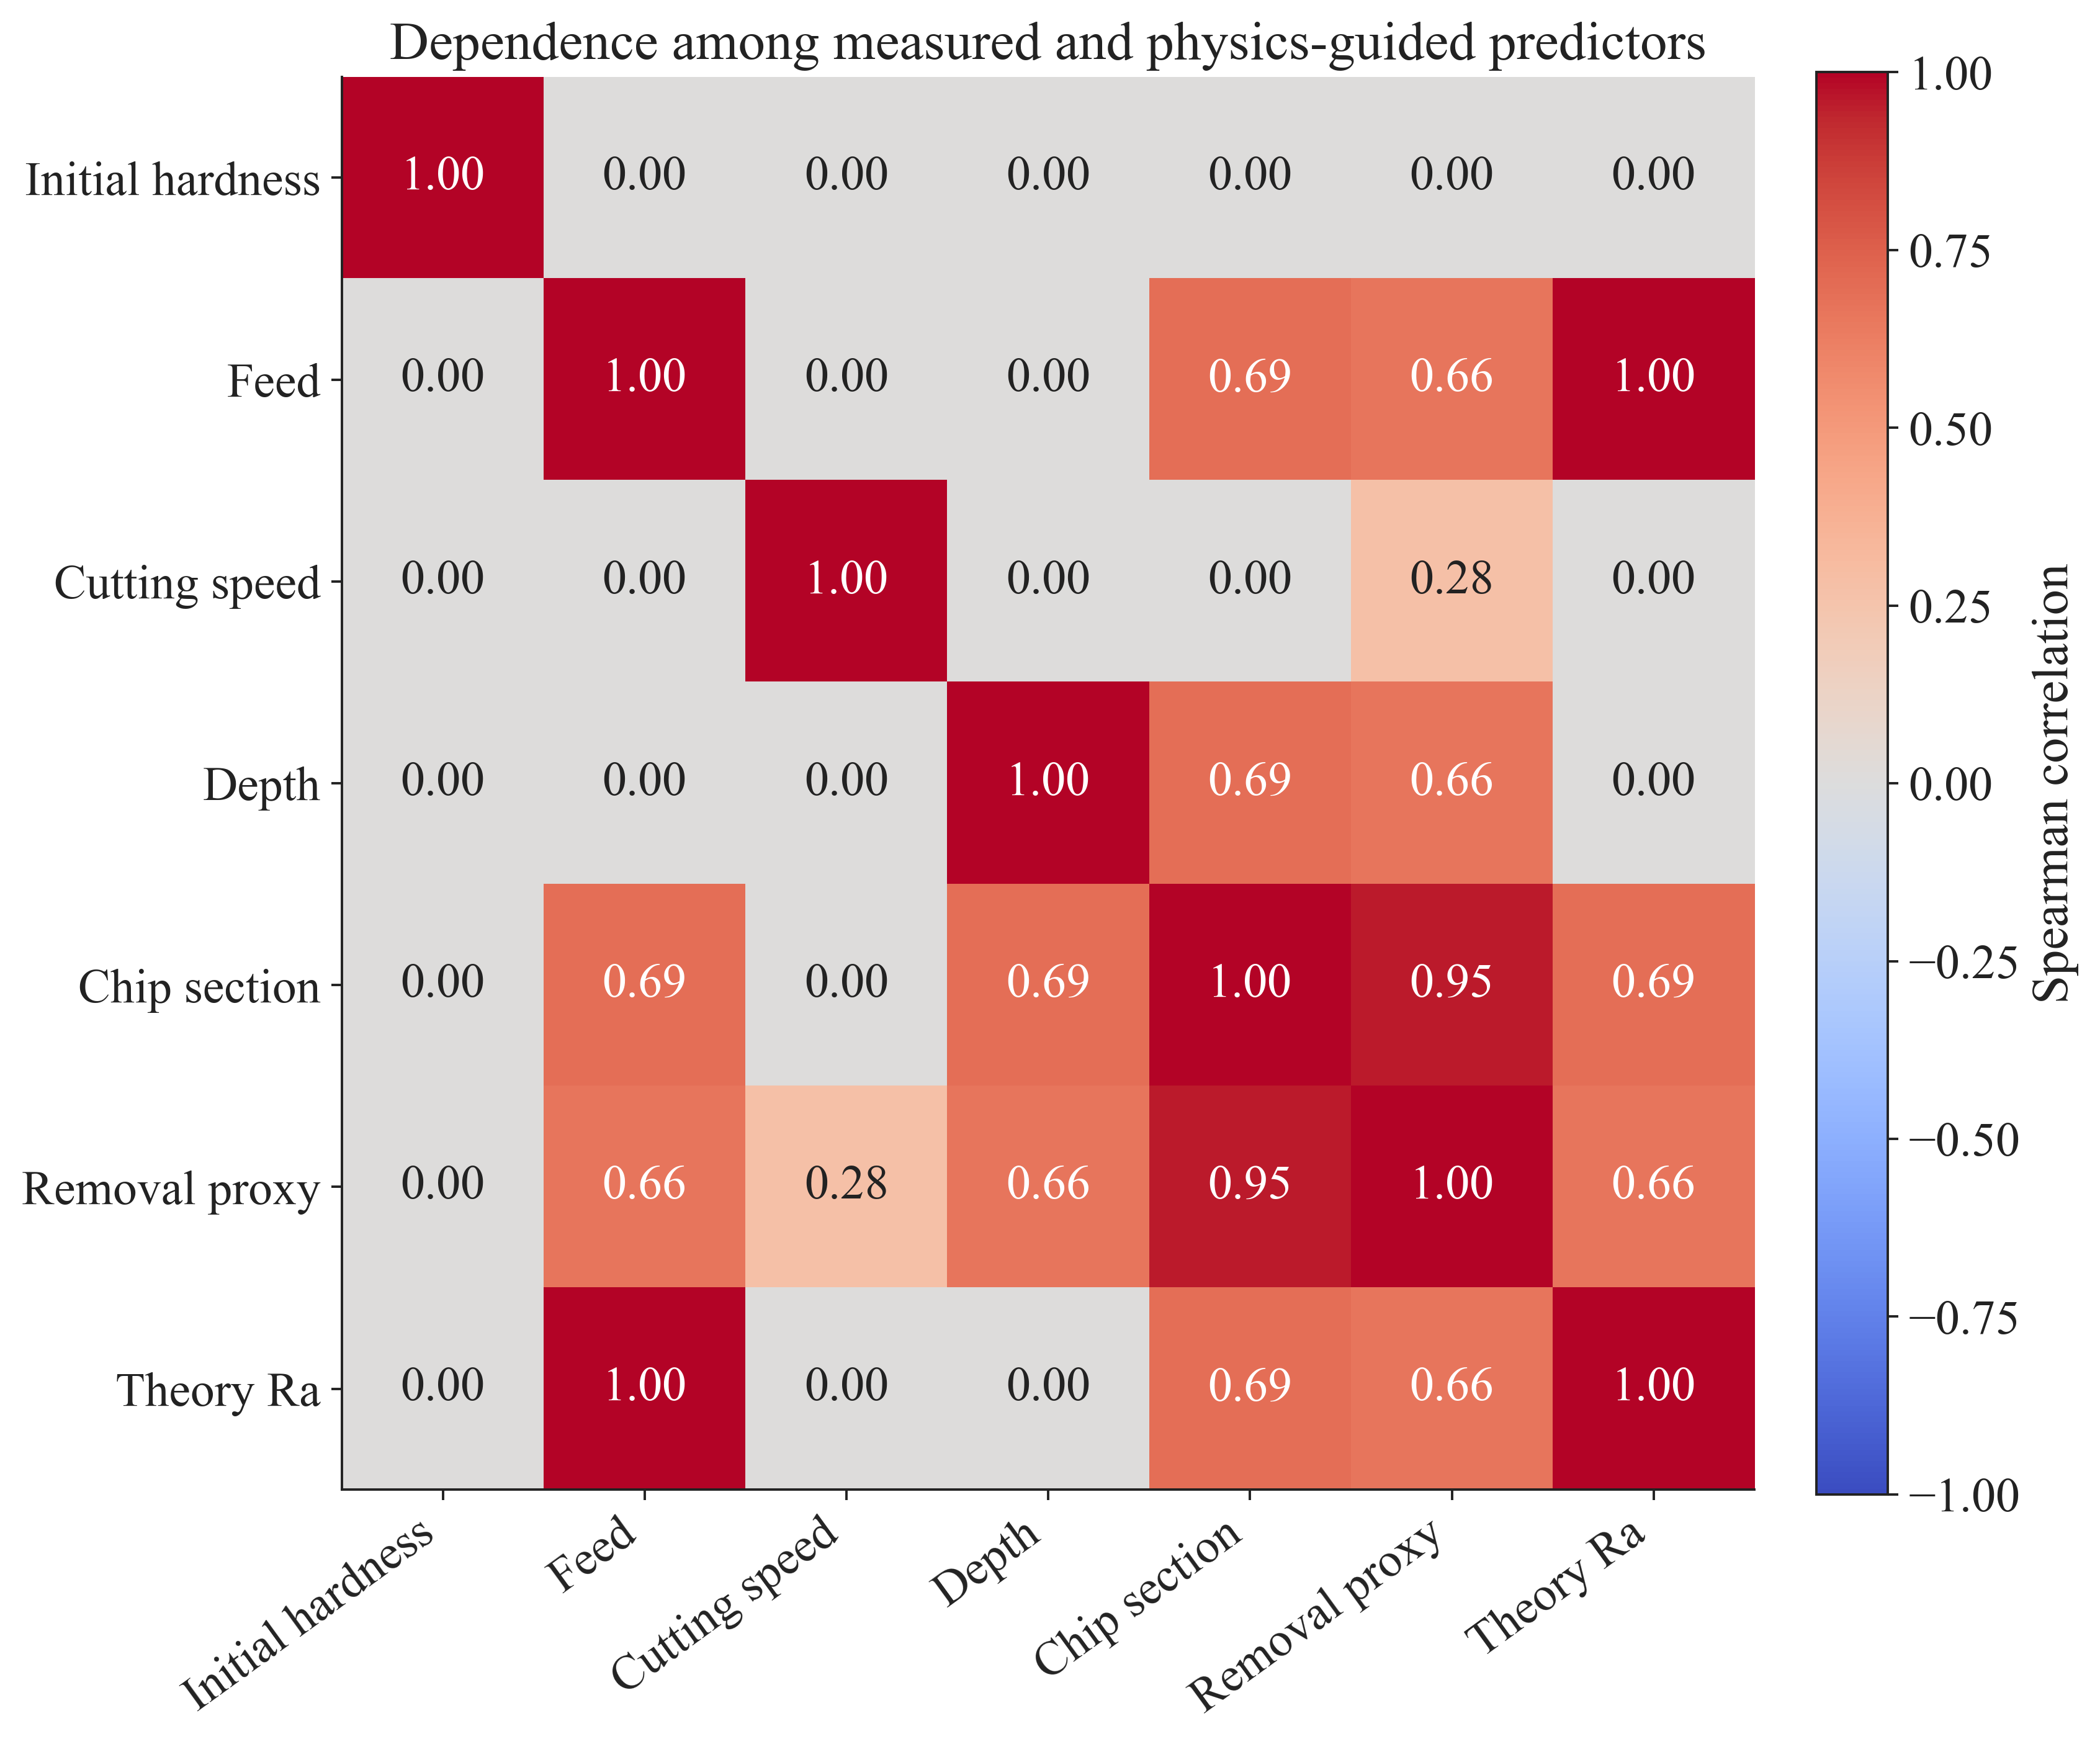

In [15]:
short_labels = ["Initial hardness", "Feed", "Cutting speed", "Depth", "Chip section", "Removal proxy", "Theory Ra"]
fig, axis = plt.subplots(figsize=(9.6, 8.4))
image = axis.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm", aspect="equal")
axis.set_xticks(range(len(short_labels)), labels=short_labels, rotation=36, ha="right")
axis.set_yticks(range(len(short_labels)), labels=short_labels)
axis.set_title("Dependence among measured and physics-guided predictors")
axis.grid(False)
for row in range(len(short_labels)):
    for column in range(len(short_labels)):
        value = correlation.iloc[row, column]
        axis.text(column, row, format_scientific_number(value, decimals=2),
                  ha="center", va="center", fontsize=16,
                  color="white" if abs(value) > 0.55 else PALETTE["black"])
colorbar = fig.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
colorbar.set_label("Spearman correlation")
colorbar.ax.tick_params(labelsize=16)
fig.tight_layout()
save_scientific_figure(fig, "preprocessing_feature_dependence", correlation.reset_index())
display(fig)
plt.close(fig)

Strong dependencies are expected because the engineered features are deterministic products or powers of the measured factors. They are retained as alternative inductive representations, but regularization and model selection must occur inside inner folds. Global correlation-based feature removal would use all observations and is therefore not applied.


## 7. Freeze nine balanced outer folds without target-based allocation


In [16]:
group_table = modeling.groupby("specimen_id", as_index=False).agg(
    HV_init_HV30=("HV_init_HV30", "first"), rows=("sample_id", "size")
)
assert group_table.rows.eq(3).all()

rng = np.random.default_rng(SEED)
group_fold_rows = []
for hardness in sorted(group_table.HV_init_HV30.unique()):
    groups = group_table.loc[group_table.HV_init_HV30.eq(hardness), "specimen_id"].to_numpy()
    assert len(groups) == 9
    for outer_fold, specimen_id in enumerate(rng.permutation(groups), start=1):
        group_fold_rows.append({"specimen_id": specimen_id, "outer_fold": outer_fold})

group_folds = pd.DataFrame(group_fold_rows)
modeling = modeling.merge(group_folds, on="specimen_id", validate="many_to_one")
modeling["split"] = "nested_group_cv"

previous_path = UNIFIED_DIR / "split_assignments.csv"
if previous_path.exists():
    previous = pd.read_csv(previous_path)[["sample_id", "outer_fold"]].sort_values("sample_id")
    current = modeling[["sample_id", "outer_fold"]].sort_values("sample_id")
    assert previous.reset_index(drop=True).equals(current.reset_index(drop=True)), (
        "The immutable outer-fold assignment changed."
    )

split_summary = modeling.groupby("outer_fold", as_index=False).agg(
    heldout_observations=("sample_id", "size"),
    heldout_specimens=("specimen_id", "nunique"),
    hardness_levels=("HV_init_HV30", "nunique"),
    Ra_mean=("surface_roughness_Ra_um", "mean"),
    HV30_mean=("post_process_hardness_HV30", "mean"),
)
display_grouped_table(split_summary.round(4), "Outer-fold composition")


**Outer-fold composition — Complete table**

outer_fold,heldout_observations,heldout_specimens,hardness_levels,Ra_mean,HV30_mean
1,9,3,3,0.228300,532.888900
2,9,3,3,0.880100,546.000000
3,9,3,3,0.649400,536.777800
4,9,3,3,1.155600,536.222200
5,9,3,3,0.881100,535.222200
6,9,3,3,1.682800,554.222200
7,9,3,3,1.975900,545.555600
8,9,3,3,0.820800,538.777800
9,9,3,3,1.183900,532.555600


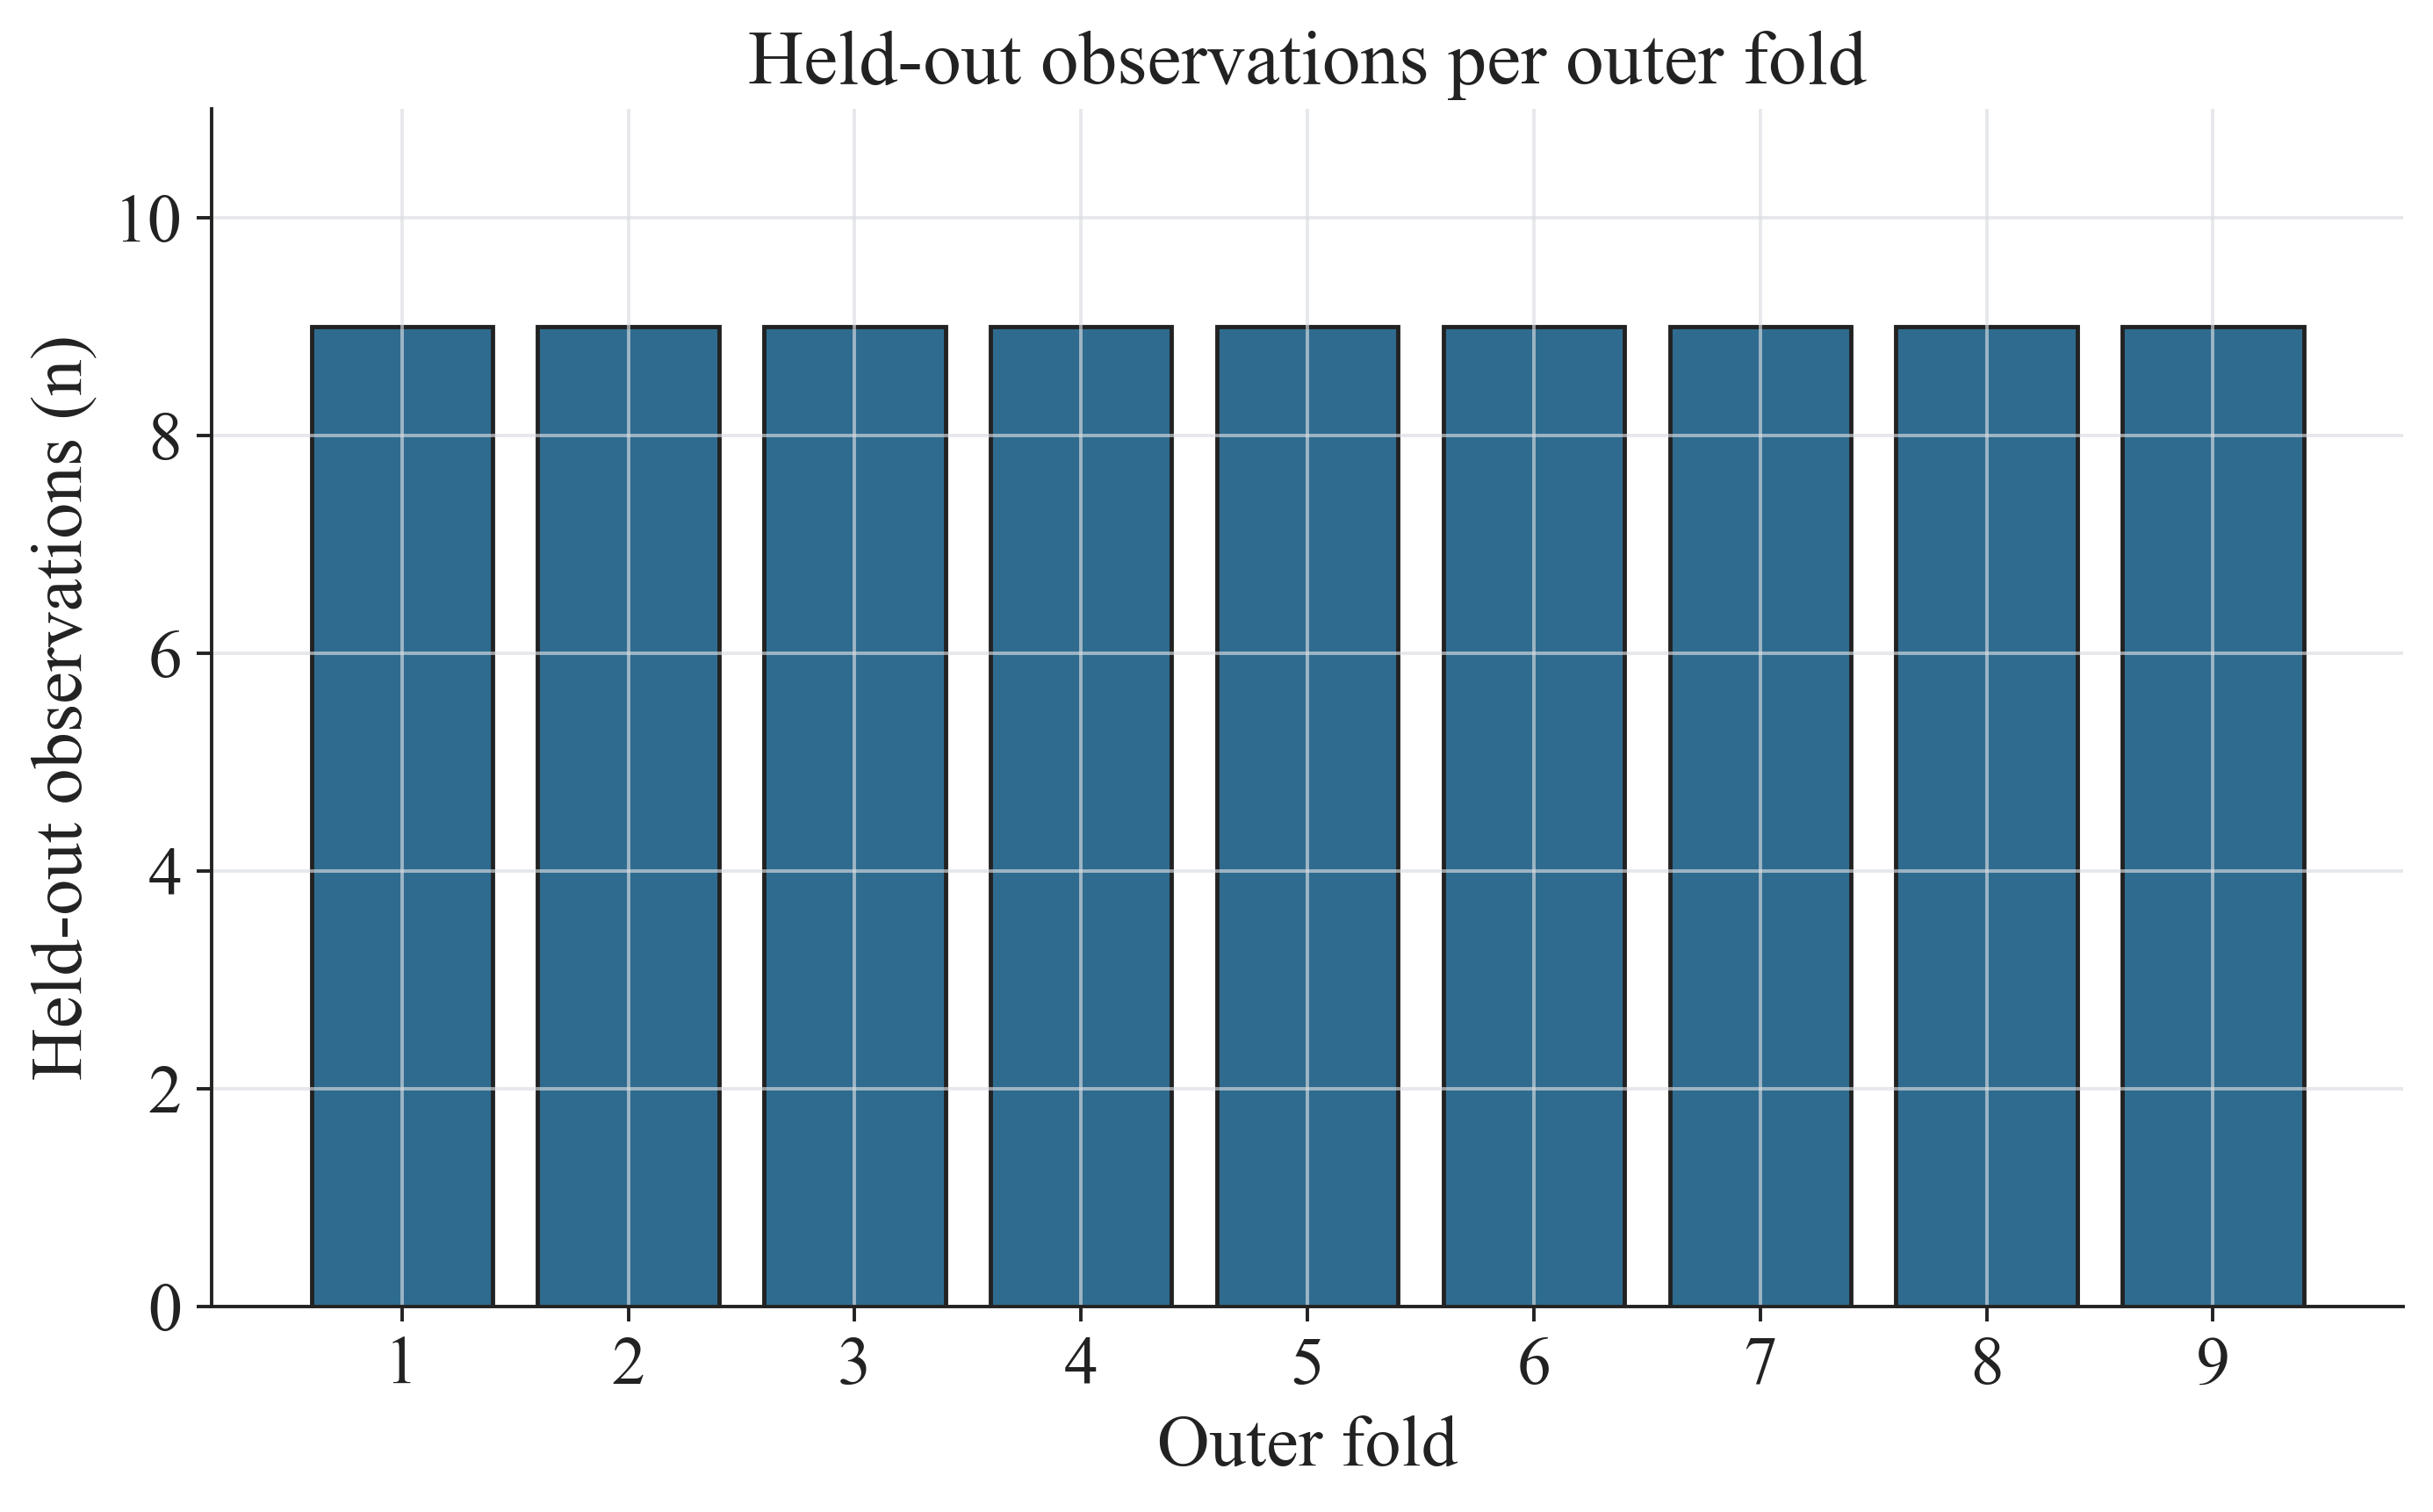

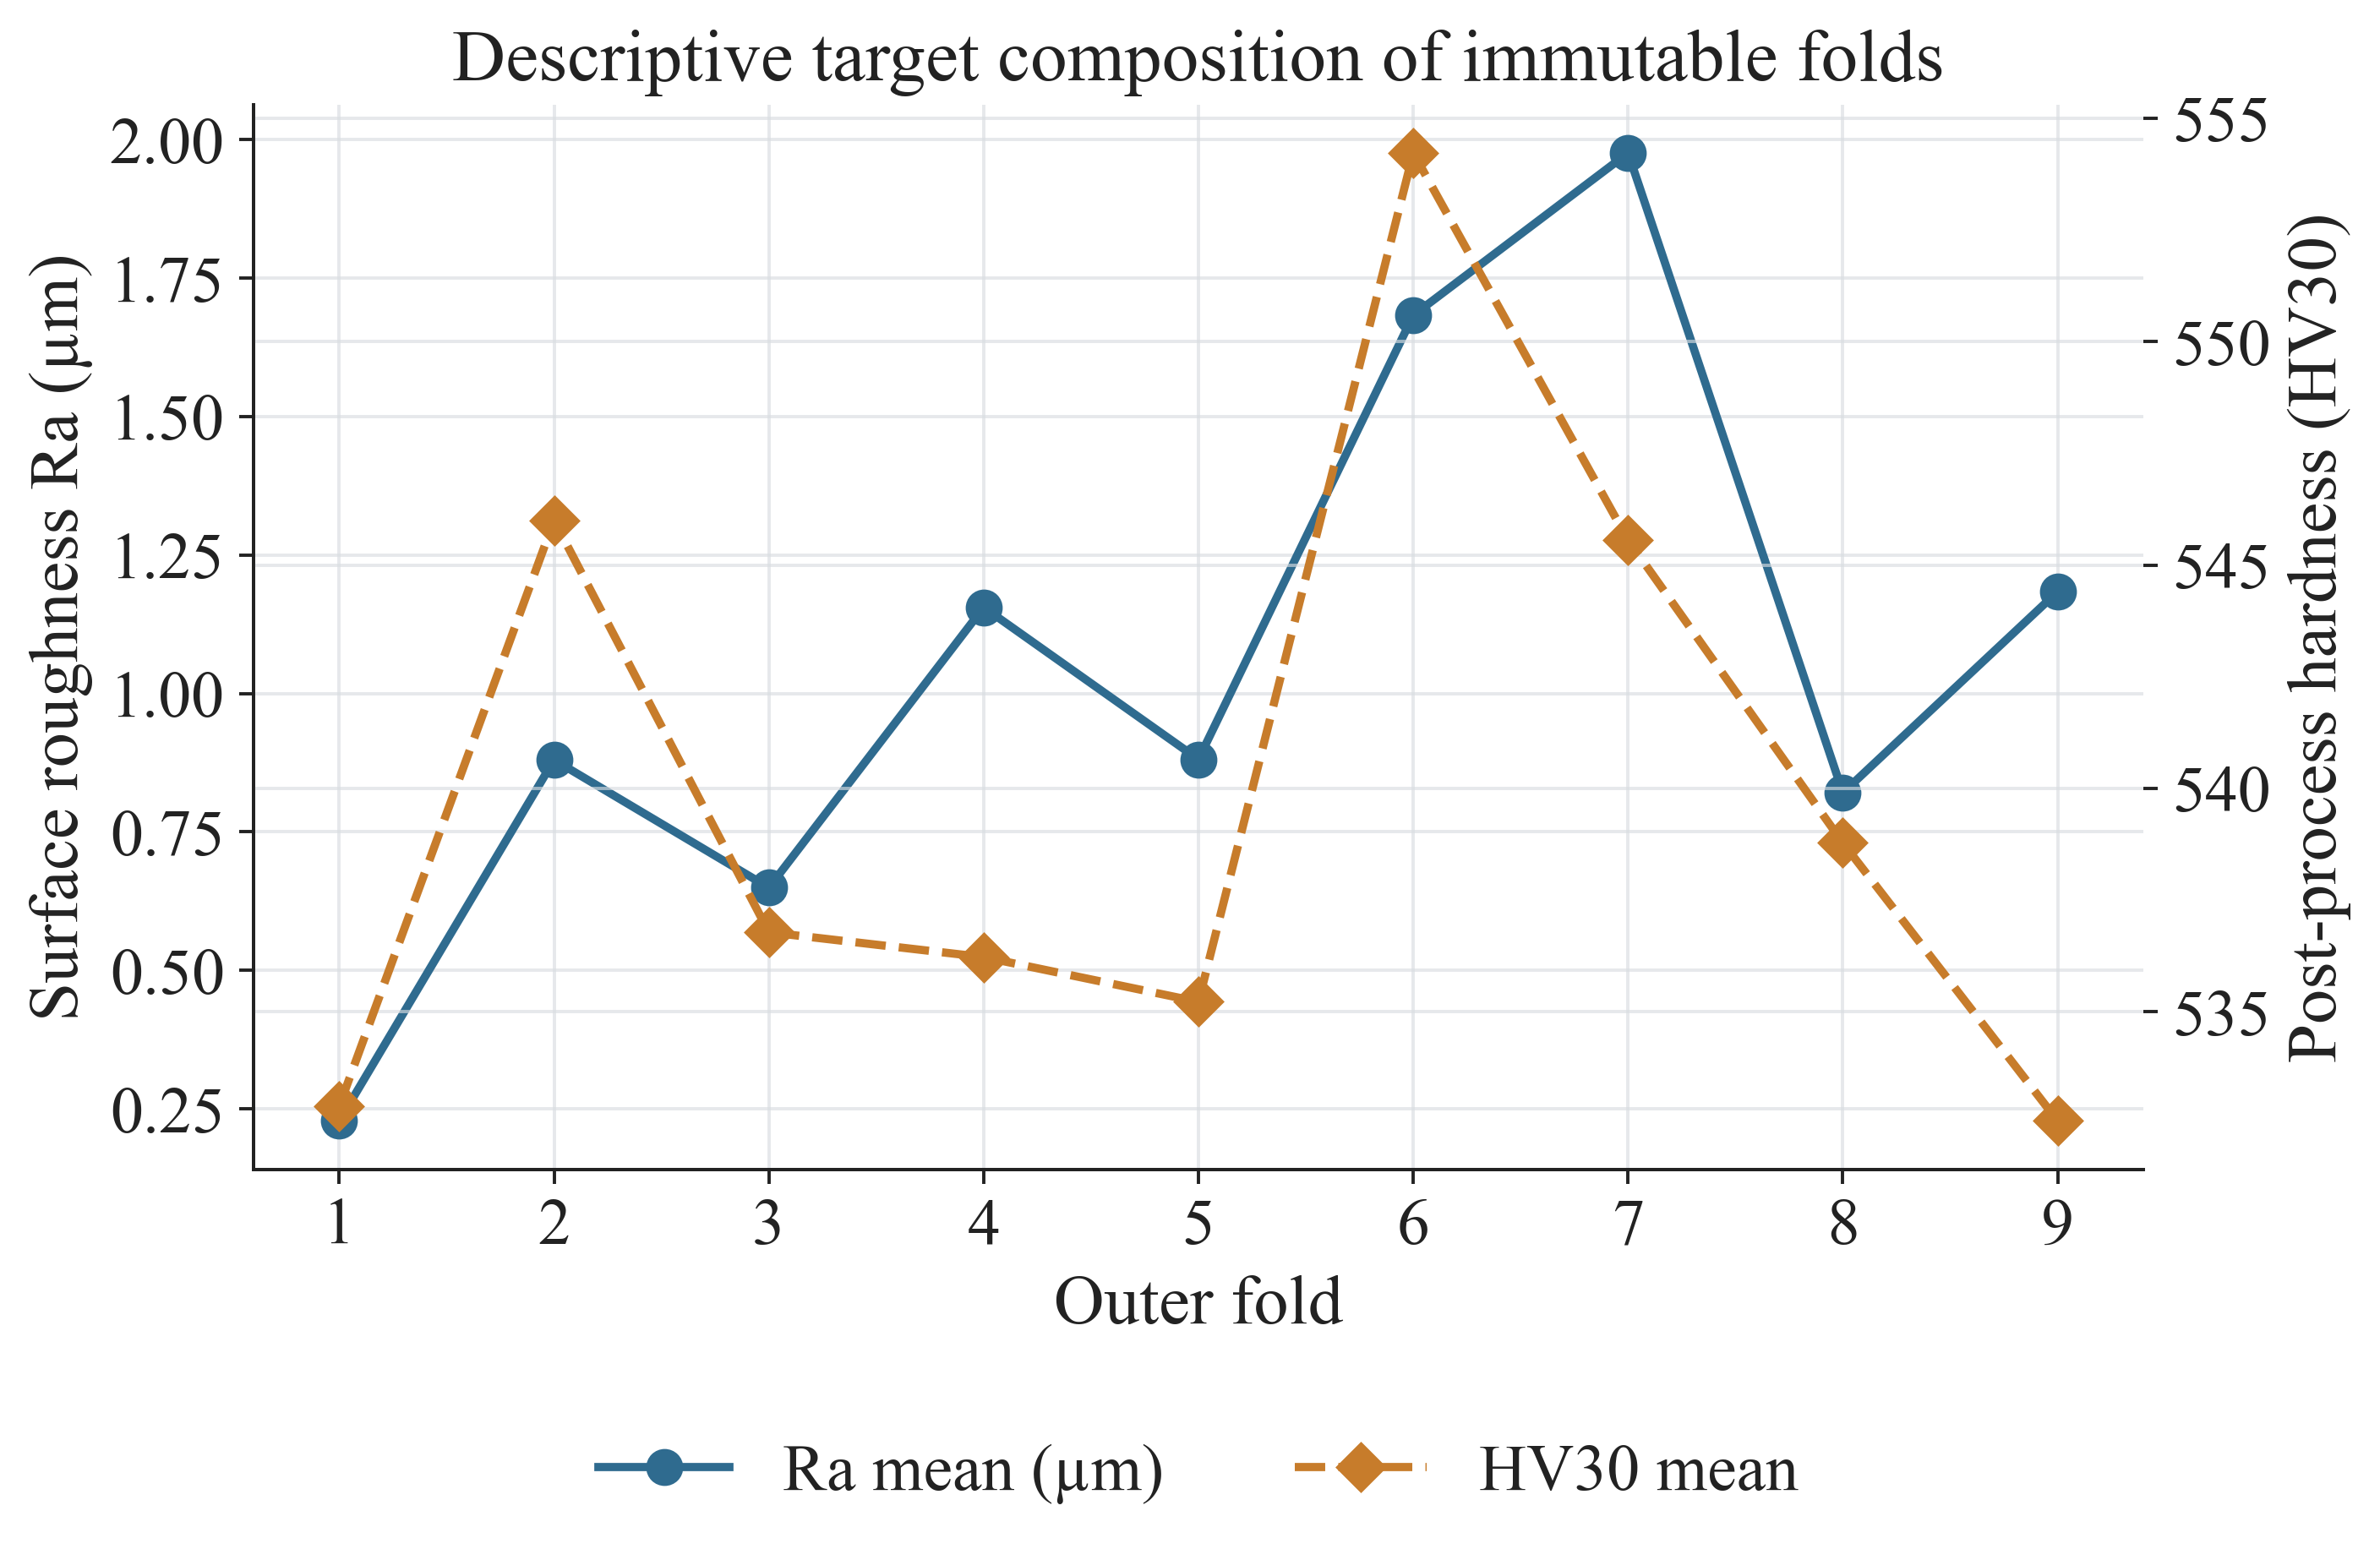

In [17]:
fig, axis = plt.subplots(figsize=(8.2, 5.2))
axis.bar(split_summary.outer_fold.astype(str), split_summary.heldout_observations,
         color=PALETTE["blue"], edgecolor=PALETTE["black"])
axis.set_title("Held-out observations per outer fold")
axis.set_xlabel("Outer fold")
axis.set_ylabel("Held-out observations (n)")
axis.set_ylim(0, 11)
fig.tight_layout()
save_scientific_figure(fig, "preprocessing_outer_fold_counts", split_summary)
display(fig)
plt.close(fig)

fig, axis = plt.subplots(figsize=(9.0, 6.0))
axis.plot(split_summary.outer_fold, split_summary.Ra_mean, marker="o",
          color=PALETTE["blue"], label="Ra mean (µm)")
second_axis = axis.twinx()
second_axis.plot(split_summary.outer_fold, split_summary.HV30_mean, marker="D",
                 linestyle="--", color=PALETTE["orange"], label="HV30 mean")
axis.set_title("Descriptive target composition of immutable folds")
axis.set_xlabel("Outer fold")
axis.set_ylabel("Surface roughness Ra (µm)")
second_axis.set_ylabel("Post-process hardness (HV30)")
axis.set_xticks(split_summary.outer_fold)
handles_a, labels_a = axis.get_legend_handles_labels()
handles_b, labels_b = second_axis.get_legend_handles_labels()
axis.legend(handles_a + handles_b, labels_a + labels_b, loc="lower center",
            bbox_to_anchor=(0.5, -0.37), ncol=2, frameon=False)
fig.subplots_adjust(left=0.15, right=0.86, top=0.88, bottom=0.28)
save_scientific_figure(fig, "preprocessing_outer_fold_target_composition", split_summary)
display(fig)
plt.close(fig)

Every outer fold contains nine rows from three specimens, including one specimen at each initial-hardness level. Targets were not used to assign folds; their displayed variation is a descriptive consequence of the small factorial sample. The immutable grouping provides one genuine OOF prediction per row while avoiding section leakage.


## 8. Verify inner grouping and compare fold-local scaling choices


In [18]:
def balanced_inner_assignment(training_frame, n_splits, seed):
    groups = training_frame[["specimen_id", "HV_init_HV30"]].drop_duplicates()
    rng_local = np.random.default_rng(seed)
    rows = []
    for hardness in sorted(groups.HV_init_HV30.unique()):
        specimens = groups.loc[groups.HV_init_HV30.eq(hardness), "specimen_id"].to_numpy()
        for position, specimen_id in enumerate(rng_local.permutation(specimens)):
            rows.append({"specimen_id": specimen_id, "inner_fold": position % n_splits})
    return pd.DataFrame(rows)

inner_records = []
for outer_fold in sorted(modeling.outer_fold.unique()):
    outer_train = modeling[modeling.outer_fold.ne(outer_fold)].reset_index(drop=True)
    assignment = balanced_inner_assignment(outer_train, 4, SEED + int(outer_fold))
    joined = outer_train.merge(assignment, on="specimen_id", validate="many_to_one")
    for inner_fold in sorted(joined.inner_fold.unique()):
        inner_train = joined[joined.inner_fold.ne(inner_fold)]
        inner_validation = joined[joined.inner_fold.eq(inner_fold)]
        assert set(inner_train.specimen_id).isdisjoint(inner_validation.specimen_id)
        inner_records.append({
            "outer_fold": outer_fold, "inner_fold": inner_fold,
            "training_observations": len(inner_train),
            "validation_observations": len(inner_validation),
            "training_specimens": inner_train.specimen_id.nunique(),
            "validation_specimens": inner_validation.specimen_id.nunique(),
        })
inner_summary = pd.DataFrame(inner_records)
inner_design = inner_summary.agg({
    "training_observations": ["min", "max"],
    "validation_observations": ["min", "max"],
    "training_specimens": ["min", "max"],
    "validation_specimens": ["min", "max"],
}).T.reset_index()
inner_design.columns = ["Quantity", "Minimum", "Maximum"]
display_grouped_table(inner_design, "Inner-fold sample sizes across all outer folds")


**Inner-fold sample sizes across all outer folds — Complete table**

Quantity,Minimum,Maximum
training_observations,54,54
validation_observations,18,18
training_specimens,18,18
validation_specimens,6,6


In [19]:
scaling_rows = []
for outer_fold in sorted(modeling.outer_fold.unique()):
    training = modeling[modeling.outer_fold.ne(outer_fold)]
    heldout = modeling[modeling.outer_fold.eq(outer_fold)]
    for scaler_name, scaler in [("StandardScaler", StandardScaler()), ("RobustScaler", RobustScaler())]:
        train_scaled = scaler.fit_transform(training[FEATURES])
        heldout_scaled = scaler.transform(heldout[FEATURES])
        scaling_rows.append({
            "Outer fold": outer_fold, "Scaler": scaler_name,
            "Mean absolute held-out center": np.mean(np.abs(np.median(heldout_scaled, axis=0))),
            "Maximum absolute held-out value": np.max(np.abs(heldout_scaled)),
            "Finite transformed values": bool(np.isfinite(train_scaled).all() and np.isfinite(heldout_scaled).all()),
        })
scaling_diagnostics = pd.DataFrame(scaling_rows)
scaling_summary = scaling_diagnostics.groupby("Scaler", as_index=False).agg(
    folds=("Outer fold", "nunique"),
    mean_heldout_center_shift=("Mean absolute held-out center", "mean"),
    maximum_heldout_absolute_value=("Maximum absolute held-out value", "max"),
    all_values_finite=("Finite transformed values", "all"),
)
display_grouped_table(scaling_summary.round(4), "Fold-local scaling diagnostics")


**Fold-local scaling diagnostics — Complete table**

Scaler,folds,mean_heldout_center_shift,maximum_heldout_absolute_value,all_values_finite
RobustScaler,9,0.211100,4.325600,True
StandardScaler,9,0.510200,4.017700,True


All 36 inner validation partitions preserve specimen separation; balanced allocation of 24 training specimens into four folds gives identical six-specimen validation partitions. Both scalers remain numerically stable. The frozen preprocessing rule is model-specific: `StandardScaler` for scale-sensitive linear, kernel, and neural models; no scaling for tree ensembles; and training-only categorical encoding for the factorial branch.


## 9. Save the immutable modeling contract


In [20]:
split_assignments = modeling[[
    "sample_id", "specimen_id", "section_id", "HV_init_HV30", "outer_fold",
    "split",
]].copy()
modeling_path = UNIFIED_DIR / "modeling_dataset.csv"
modeling.to_csv(modeling_path, index=False)
split_assignments.to_csv(UNIFIED_DIR / "split_assignments.csv", index=False)

preprocessing_summary = pd.DataFrame([
    {"Contract item": "Experimental design", "Frozen value": "Balanced hierarchical split-plot factorial design"},
    {"Contract item": "Prediction / inferential units", "Frozen value": "81 section rows / 27 physical specimens"},
    {"Contract item": "Measured / derived predictors", "Frozen value": "4 / 3"},
    {"Contract item": "Targets", "Frozen value": "Ra (µm); post-process hardness (HV30)"},
    {"Contract item": "Missing-value handling", "Frozen value": "None required"},
    {"Contract item": "Outer / inner CV", "Frozen value": "9 specimen-group folds / 4 specimen-group folds"},
    {"Contract item": "Scaling", "Frozen value": "Fit inside each training partition; StandardScaler only for scale-sensitive models"},
    {"Contract item": "Independent validation", "Frozen value": "Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified"},
    {"Contract item": "Primary ordering metric", "Frozen value": "Mean target-wise NRMSE; physical-unit metrics remain separate"},
])
preprocessing_summary.to_csv(UNIFIED_DIR / "preprocessing_summary.csv", index=False)

reloaded = pd.read_csv(modeling_path)
assert reloaded.shape == modeling.shape
assert reloaded.groupby("specimen_id").outer_fold.nunique().eq(1).all()
display_grouped_table(preprocessing_summary, "Frozen preprocessing and resampling contract")


**Frozen preprocessing and resampling contract — Complete table**

Contract item,Frozen value
Experimental design,Balanced hierarchical split-plot factorial design
Prediction / inferential units,81 section rows / 27 physical specimens
Measured / derived predictors,4 / 3
Targets,Ra (µm); post-process hardness (HV30)
Missing-value handling,None required
Outer / inner CV,9 specimen-group folds / 4 specimen-group folds
Scaling,Fit inside each training partition; StandardScaler only for scale-sensitive models
Independent validation,Not performed; no methodologically compatible independent dataset with paired Ra/HV30 outcomes was identified
Primary ordering metric,Mean target-wise NRMSE; physical-unit metrics remain separate


## Limitations and hand-off

The complete factorial grid provides unusually strong coverage of the observed process domain, but there is no replication of a four-factor condition and only 27 independent specimens. The high descriptive ICC confirms that section rows cannot be treated as independent. Engineered predictors are deterministic and correlated, so their usefulness must be judged only through inner-CV regularization; the frozen outer folds are an evaluation contract, not an independent test.

No methodologically compatible independent dataset containing the required process structure and paired Ra/HV30 outcomes was identified. Therefore, independent external validation was not performed. The study relies on leakage-safe specimen-grouped nested cross-validation and complementary internal robustness analyses, and all conclusions are restricted to the investigated 51CrV4 factorial domain. Internal validation does not replace independent validation. Notebook 03 must use only the immutable primary modeling contract and may select model configurations inside training-side inner folds only.
